# Solutions to notebook 13: Neumann, Robin and mixed boundary conditions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/13_boundary_conditions.ipynb)

Worked solutions to the exercises at the end of [notebook 13](../notebooks/13_boundary_conditions.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct
from scipy.linalg import eig
from scipy.optimize import brentq
from scipy.special import jv

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))
    D -= np.diag(D.sum(axis=1))
    return D, x

# barycentric_interpolate(values, x_eval) from notebook 4
def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

# clenshaw_curtis(N) from notebook 10
def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

# rk4_step(f, u, dt) from notebook 9
def rk4_step(f, u, dt):
    k1 = f(u)
    k2 = f(u + dt / 2 * k1)
    k3 = f(u + dt / 2 * k2)
    k4 = f(u + dt * k3)
    return u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def cheb_unit(N):
    """Helper for these solutions: cheb(N) mapped to [0, 1]. Index 0 is x = 1 and index N is x = 0."""
    D, xi = cheb(N)
    return 2 * D, (xi + 1) / 2

def lowest_modes(A, B, count=3):
    """Helper for these solutions: the smallest finite, real, positive eigenvalues of A φ = λ B φ and their eigenvectors."""
    values, vectors = eig(A, B)
    keep = np.isfinite(values) & (np.abs(values.imag) < 1e-8) & (values.real > 0)
    order = np.argsort(values.real[keep])[:count]
    return values.real[keep][order], vectors.real[:, keep][:, order]

## Exercise 1

A rod on $0 \le x \le 1$ with internal heating obeys $\theta'' + e^{2x} = 0$. A heater
supplies the flux $-\theta'(0) = 2$ at the left end and the right end is held at
$\theta(1) = 0$. Solve with $N = 16$ using a Neumann row and a Dirichlet row, find the exact
solution by integrating twice, and report the largest error and the temperature at $x = 0$.

Map the grid to $[0, 1]$. The left end $x = 0$ is index $N$ and gets a Neumann row,
$\theta'(0) = -2$. The right end $x = 1$ is index 0 and gets a Dirichlet row. By hand:
integrating once, $\theta' = -\tfrac12e^{2x} + C$, and $\theta'(0) = -2$ gives $C = -\tfrac32$.
Integrating again and using $\theta(1) = 0$,

$$\theta(x) = \frac{e^2 - e^{2x}}{4} + \frac{3(1 - x)}{2},\qquad \theta(0) = \frac{e^2 - 1}{4} + \frac32 .$$

largest error: 9.0e-14    θ(0) = 3.097264024733    exact (e² − 1)/4 + 3/2 = 3.097264024733


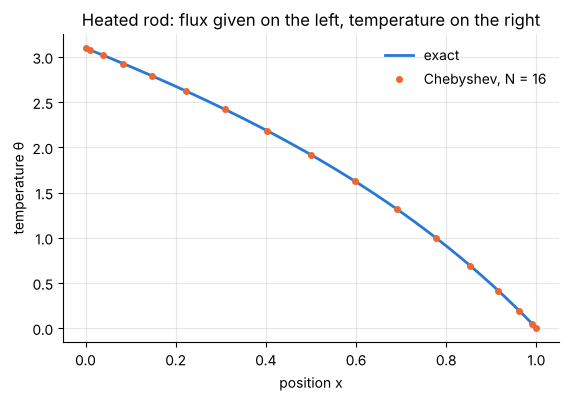

In [3]:
N = 16
D, x = cheb_unit(N)
A = D @ D                                            # θ'' = -exp(2x) in every row, for now
rhs = -np.exp(2 * x)
A[N, :], rhs[N] = D[N, :], -2.0                      # row N, the left end x = 0: θ' = -2
A[0, :] = 0.0                                        # row 0, the right end x = 1: θ = 0
A[0, 0], rhs[0] = 1.0, 0.0
theta = np.linalg.solve(A, rhs)
rod_exact = lambda x: (np.exp(2) - np.exp(2 * x)) / 4 + 3 * (1 - x) / 2
rod_error = np.abs(theta - rod_exact(x)).max()
print(f"largest error: {rod_error:.1e}    θ(0) = {theta[N]:.12f}    exact (e² − 1)/4 + 3/2 = {(np.exp(2) - 1) / 4 + 1.5:.12f}")

x_fine = np.linspace(0, 1, 200)
fig, ax = plt.subplots()
ax.plot(x_fine, rod_exact(x_fine), label="exact")
ax.plot(x, theta, "o", ms=4, label="Chebyshev, N = 16")
ax.set(xlabel="position x", ylabel="temperature θ", title="Heated rod: flux given on the left, temperature on the right")
ax.legend(frameon=False, loc="upper right");

In [4]:
# verify: the exact solution, both boundary conditions, and the overall heat balance
assert rod_error < 1e-10
assert abs((D @ theta)[N] + 2) < 1e-10 and abs(theta[0]) < 1e-12
w = clenshaw_curtis(N)[1] / 2                        # weights for [0, 1]
heat_out = -(D @ theta)[0]                           # flux leaving at x = 1
print(f"heat leaving at x = 1: {heat_out:.10f}    heater + internal heating: {2 + w @ np.exp(2 * x):.10f}")
assert abs(heat_out - (2 + (np.exp(2) - 1) / 2)) < 1e-10

heat leaving at x = 1: 5.1945280495    heater + internal heating: 5.1945280495


**Answer.** The exact solution is $\theta = (e^2 - e^{2x})/4 + 3(1 - x)/2$. With $N = 16$ the
largest error is $9\times10^{-14}$ and the temperature at the heated end is
$\theta(0) = (e^2 - 1)/4 + \tfrac32 = 3.097264$. The heat leaving at $x = 1$ is 5.1945, the sum
of the heater flux 2 and the internal heating $(e^2 - 1)/2$, so the energy balance closes. The
Neumann row is as accurate as the Dirichlet row.

## Exercise 2

Critical radius of insulation. A pipe of outer radius 1 at $\theta = 1$ is covered with
insulation out to radius $r_o$, whose surface loses heat by convection:
$\theta'' + \theta'/r = 0$ on $1 \le r \le r_o$, $\theta(1) = 1$,
$\theta'(r_o) + \mathrm{Bi}\,\theta(r_o) = 0$ with $\mathrm{Bi} = 0.25$. Solve on a Chebyshev
grid mapped to $[1, r_o]$ with $N = 16$ for $r_o = 1.5, 2, 2.5, \dots, 8$, and compute the
heat loss per unit length $Q = -2\pi\,\theta'(1)$ for each. Compare with the exact
$Q = 2\pi/\big(\ln r_o + 1/(\mathrm{Bi}\,r_o)\big)$. At which $r_o$ is the loss largest, and
how does it compare with the loss from the bare pipe, $2\pi\,\mathrm{Bi}$?

Map the grid to $r = 1 + (r_o - 1)(x + 1)/2$, which multiplies $D$ by $2/(r_o - 1)$. The outer
surface $r = r_o$ is index 0 and gets the Robin row. The pipe wall $r = 1$ is index $N$ and
gets the Dirichlet row, and $\theta'(1)$ is row $N$ of $D\boldsymbol\theta$. The exact
solution is $\theta = 1 - Q\ln r/(2\pi)$, and setting $dQ/dr_o = 0$ in the exact formula gives
the critical radius $r_o = 1/\mathrm{Bi} = 4$.

  r_o      Q computed       error      Q / Q bare
  1.5    2.0452199866     1.6e-12      1.3020
  2.0    2.3330270817     2.9e-14      1.4853
  2.5    2.4970029208     8.0e-11      1.5896
  3.0    2.5836043562     1.7e-09      1.6448
  3.5    2.6227803162     1.4e-08      1.6697
  4.0    2.6330302074     7.1e-08      1.6762
  4.5    2.6256887669     2.6e-07      1.6716
  5.0    2.6077383199     7.2e-07      1.6601
  5.5    2.5835227693     1.7e-06      1.6447
  6.0    2.5557719653     3.5e-06      1.6271
  6.5    2.5262150649     6.7e-06      1.6082
  7.0    2.4959518429     1.2e-05      1.5890
  7.5    2.4656807828     1.9e-05      1.5697
  8.0    2.4358414042     2.9e-05      1.5507
largest loss at r_o = 4.0: Q = 2.633030, bare pipe 1.570796, ratio 1.6762


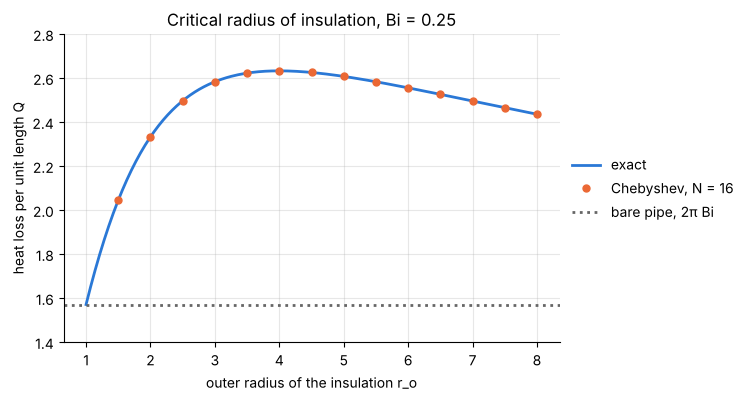

In [5]:
def insulated_pipe(N, r_outer, Bi):
    """Conduction in the insulation, 1 ≤ r ≤ r_outer, with convection outside. Returns r, θ and the heat loss Q."""
    D, xi = cheb(N)
    D, r = 2 / (r_outer - 1) * D, 1 + (r_outer - 1) * (xi + 1) / 2
    A = D @ D + np.diag(1 / r) @ D
    rhs = np.zeros(N + 1)
    A[0, :] = D[0, :]                                # row 0, the outer surface r = r_outer: θ' + Bi θ = 0
    A[0, 0] += Bi
    A[N, :] = 0.0                                    # row N, the pipe wall r = 1: θ = 1
    A[N, N], rhs[N] = 1.0, 1.0
    theta = np.linalg.solve(A, rhs)
    return r, theta, -2 * np.pi * (D @ theta)[N]

Bi = 0.25
radii = np.arange(1.5, 8.01, 0.5)
Q = np.array([insulated_pipe(16, r_outer, Bi)[2] for r_outer in radii])
Q_exact = lambda r_outer: 2 * np.pi / (np.log(r_outer) + 1 / (Bi * r_outer))
Q_bare = 2 * np.pi * Bi
print("  r_o      Q computed       error      Q / Q bare")
for r_outer, q in zip(radii, Q):
    print(f"{r_outer:5.1f} {q:15.10f} {abs(q - Q_exact(r_outer)):11.1e} {q / Q_bare:11.4f}")
r_worst = radii[Q.argmax()]
print(f"largest loss at r_o = {r_worst}: Q = {Q.max():.6f}, bare pipe {Q_bare:.6f}, ratio {Q.max() / Q_bare:.4f}")

r_fine = np.linspace(1, 8, 200)
fig, ax = plt.subplots()
ax.plot(r_fine, Q_exact(r_fine), label="exact")
ax.plot(radii, Q, "o", ms=5, label="Chebyshev, N = 16")
ax.axhline(Q_bare, color="0.4", ls=":", label="bare pipe, 2π Bi")
ax.set(xlabel="outer radius of the insulation r_o", ylabel="heat loss per unit length Q", ylim=(1.4, 2.8),
       title="Critical radius of insulation, Bi = 0.25")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [6]:
# verify: the exact heat loss for every radius, the critical radius 1/Bi, and the Robin condition itself
assert np.abs(Q - Q_exact(radii)).max() < 5e-5 and np.abs(Q - Q_exact(radii))[radii <= 4].max() < 1e-7
assert abs(insulated_pipe(32, 8.0, Bi)[2] - Q_exact(8.0)) < 1e-9          # the worst case, r_o = 8, converges with N
assert r_worst == 1 / Bi and abs(Q.max() / Q_bare - 4 / (np.log(4) + 1)) < 1e-7
r, theta, _ = insulated_pipe(16, 4.0, Bi)
assert np.abs(theta - (1 - Q_exact(4.0) * np.log(r) / (2 * np.pi))).max() < 1e-7
assert (Q > Q_bare).all()                            # every thickness in the list loses more heat than no insulation

**Answer.** The heat loss is largest at $r_o = 4 = 1/\mathrm{Bi}$, the critical radius, where
$Q = 2.6330$ against $2\pi\,\mathrm{Bi} = 1.5708$ for the bare pipe: insulating the pipe out to
the critical radius raises the loss by 68 %. Every thickness in the list loses more heat than
no insulation at all, because the larger surface area helps convection more than the added
layer hinders conduction. Only when $\mathrm{Bi}$, based on the pipe radius, is at least 1 does
every added layer reduce the loss, which is the case for steam pipes but not for thin wires.
The error of the
computed $Q$ with $N = 16$ grows from $10^{-12}$ at $r_o = 1.5$ to $7\times10^{-8}$ at
$r_o = 4$ and $3\times10^{-5}$ at $r_o = 8$: the solution is $\ln r$, whose singularity at
$r = 0$ lies closer to the interval, in the mapped variable, the larger $r_o$ is. With
$N = 32$ the error at $r_o = 8$ is below $10^{-9}$.

## Exercise 3

A vertical column clamped at its base and free at the top buckles under its own weight when
the eigenvalue problem $\theta'' + \lambda\,x\,\theta = 0$ on $0 \le x \le 1$, with
$\theta'(0) = 0$ at the free top and $\theta(1) = 0$ at the base, has a non-zero solution.
Here $\theta$ is the slope of the column and $\lambda = qL^3/EI$, with $q$ the weight per
unit length. Formulate it as a generalized eigenvalue problem with one Neumann and one
Dirichlet row and compute the smallest $\lambda$. The classical value is 7.8373. How tall
can a steel tube be ($E = 200$ GPa, outer diameter 50 mm, wall thickness 2 mm, density
7850 kg/m³, $g = 9.81$ m/s²) before it buckles under its own weight?

Write the equation as $-\theta'' = \lambda\,x\,\theta$. On the grid mapped to $[0, 1]$ this is
$A\boldsymbol\theta = \lambda B\boldsymbol\theta$ with $A = -D^2$ and $B = \operatorname{diag}(x_i)$.
The base $x = 1$ is index 0: row 0 of $A$ becomes a row of the identity. The top $x = 0$ is
index $N$: row $N$ of $A$ becomes row $N$ of $D$. Both rows of $B$ are set to zero. For the
tube, $q = \rho gA_s$ with $A_s$ the area of the cross-section, so
$L = (\lambda EI/\rho gA_s)^{1/3}$. The classical solution is in Bessel functions of order
$-\tfrac13$: $\lambda = \big(\tfrac32z_1\big)^2$, where $z_1$ is the first zero of $J_{-1/3}$,
which gives an independent check.

In [7]:
def column_eigenvalue(N):
    """Smallest λ of θ'' + λ x θ = 0 with θ'(0) = 0 and θ(1) = 0, and its mode on the grid."""
    D, x = cheb_unit(N)
    A, B = -D @ D, np.diag(x)
    A[0, :] = 0.0                                    # row 0, the base x = 1: θ = 0
    A[0, 0] = 1.0
    A[N, :] = D[N, :]                                # row N, the free top x = 0: θ' = 0
    B[0, 0] = B[N, N] = 0.0                          # no eigenvalue in the boundary rows
    values, vectors = lowest_modes(A, B, count=1)
    return values[0], vectors[:, 0], x

print("   N      smallest λ")
for N in (8, 12, 16, 24):
    print(f"{N:4d} {column_eigenvalue(N)[0]:16.10f}")
lam_column, mode, x = column_eigenvalue(24)
z_1 = brentq(lambda z: jv(-1 / 3, z), 1.0, 3.0, xtol=1e-14)
print(f"from the first zero of J₋₁⸝₃: λ = {(1.5 * z_1) ** 2:.10f}")

E_steel, rho, g = 200e9, 7850.0, 9.81                # Pa, kg/m³, m/s²
d_outer, wall = 0.050, 0.002                         # m
d_inner = d_outer - 2 * wall
area = np.pi / 4 * (d_outer**2 - d_inner**2)         # m²
inertia = np.pi / 64 * (d_outer**4 - d_inner**4)     # m⁴
weight = rho * g * area                              # N/m
height = (lam_column * E_steel * inertia / weight) ** (1 / 3)
print(f"tube: area {area * 1e6:.1f} mm², I = {inertia * 1e8:.3f} cm⁴, weight {weight:.2f} N/m, critical height {height:.2f} m")

   N      smallest λ
   8     7.8373560253
  12     7.8373474282
  16     7.8373474389
  24     7.8373474389
from the first zero of J₋₁⸝₃: λ = 7.8373474389
tube: area 301.6 mm², I = 8.701 cm⁴, weight 23.23 N/m, critical height 18.04 m


In [8]:
# verify: the classical value, the Bessel-function solution, a finer grid, and the equation satisfied by the mode
assert round(lam_column, 4) == 7.8373
assert abs(lam_column - (1.5 * z_1) ** 2) < 1e-9
assert abs(column_eigenvalue(32)[0] - lam_column) < 1e-9
shape = mode / mode[-1]                              # scaled to 1 at the top, x = 0 (index N)
bessel_shape = lambda s: np.sqrt(s) * jv(-1 / 3, z_1 * s**1.5)
assert np.abs(shape[:-1] - bessel_shape(x[:-1]) / bessel_shape(1e-12)).max() < 1e-8
height_by_hand = (7.8373 * 200e9 * (0.050**2 + 0.046**2) / 16 / (7850 * 9.81)) ** (1 / 3)      # with I/A = (d_o² + d_i²)/16
assert abs(height - height_by_hand) < 1e-3

**Answer.** $\lambda = 7.837347$, which rounds to the classical 7.8373 and agrees with the
Bessel-function solution $\big(\tfrac32z_1\big)^2$ to ten digits. For the tube
$I/A_s = (d_o^2 + d_i^2)/16$, the weight is 23.2 N/m, and the critical height is
$L = (\lambda EI/q)^{1/3} = 18.0$ m. The result depends on the cube root of the stiffness, so a
material twice as stiff stands only 26 % taller. Real masts and tubes of that height need a
safety margin, guy wires or a taper.

## Exercise 4

A bar carrying longitudinal waves is fixed at $x = 0$ and attached to a spring at $x = 1$:
$-u'' = \mu^2 u$, $u(0) = 0$, $u'(1) + 2u(1) = 0$. Compute the first three natural
frequencies $\mu$ with $N = 24$ and check them against the roots of the transcendental
equation you derive by hand. Between which two classical cases (free end, fixed end) do they
lie?

By hand: $u(0) = 0$ selects $u = \sin\mu x$, and the spring condition then requires
$\mu\cos\mu + 2\sin\mu = 0$, that is $\tan\mu = -\mu/2$. Since $\tan\mu$ must be negative,
there is one root in each interval $\big((n - \tfrac12)\pi,\ n\pi\big)$. On the grid, the spring
end $x = 1$ is index 0 and gets the Robin row, the fixed end $x = 0$ is index $N$ and gets
the Dirichlet row, and the eigenvalue of the generalized problem is $\mu^2$.

In [9]:
def spring_bar(N, stiffness, count=3):
    """Frequencies μ and modes of -u'' = μ² u with u(0) = 0 and u'(1) + stiffness u(1) = 0."""
    D, x = cheb_unit(N)
    A, B = -D @ D, np.eye(N + 1)
    A[0, :] = D[0, :]                                # row 0, the spring end x = 1: u' + stiffness u = 0
    A[0, 0] += stiffness
    A[N, :] = 0.0                                    # row N, the fixed end x = 0: u = 0
    A[N, N] = 1.0
    B[0, 0] = B[N, N] = 0.0
    values, vectors = lowest_modes(A, B, count)
    return np.sqrt(values), vectors, x

mu, modes, x = spring_bar(24, 2.0)
n = np.arange(1, 4)
mu_roots = np.array([brentq(lambda m: m * np.cos(m) + 2 * np.sin(m), (k - 0.5) * np.pi, k * np.pi, xtol=1e-14) for k in n])
print("  n    computed μ      root of μ cos μ + 2 sin μ    free end (n − ½)π    fixed end nπ")
for k in range(3):
    print(f"{k + 1:3d} {mu[k]:14.10f} {mu_roots[k]:18.10f} {(k + 0.5) * np.pi:22.6f} {(k + 1) * np.pi:16.6f}")

  n    computed μ      root of μ cos μ + 2 sin μ    free end (n − ½)π    fixed end nπ
  1   2.2889297281       2.2889297281               1.570796         3.141593
  2   5.0869850941       5.0869850941               4.712389         6.283185
  3   8.0961636032       8.0961636032               7.853982         9.424778


In [10]:
# verify: the roots of the transcendental equation, the mode shape sin(μx), and the two limits of the spring stiffness
assert np.abs(mu - mu_roots).max() < 1e-9
assert np.abs(modes[:, 0] / modes[0, 0] * np.sin(mu[0]) - np.sin(mu[0] * x)).max() < 1e-9      # index 0 is x = 1
assert ((n - 0.5) * np.pi < mu).all() and (mu < n * np.pi).all()
assert np.abs(spring_bar(24, 0.0)[0] - (n - 0.5) * np.pi).max() < 1e-8                         # no spring: free end
assert np.abs(spring_bar(24, 1e9)[0] - n * np.pi).max() < 1e-6                                 # very stiff spring: fixed end

**Answer.** $\mu_1 = 2.288930$, $\mu_2 = 5.086985$, $\mu_3 = 8.096164$, the roots of
$\tan\mu = -\mu/2$, reproduced to ten digits with $N = 24$. Each lies between the frequency of
a bar with a free end, $(n - \tfrac12)\pi$, and that of a bar with a fixed end, $n\pi$: a spring
restrains the end more than nothing and less than a wall. The higher the mode, the closer it
is to the free-end value, because a spring of given stiffness matters less and less compared
with the stiffness of the bar over a short wavelength.

## Exercise 5

A dashpot at the end $x = 1$ of the string of 13.5 gives the condition
$u_x + \beta\,u_t = 0$. Show by hand that a pulse is reflected with its amplitude multiplied
by $(1 - \beta)/(1 + \beta)$, so that $\beta = 0$, $1$ and $\infty$ are the free, absorbing
and fixed ends. Modify `wave_system` for this condition, run the pulse of 13.5 to $t = 2$
with $\beta = 3$ and $N = 80$, and confirm that one quarter of the energy remains and that
$u(x, 2) = -\tfrac12 u(x, 0)$.

**By hand.** Near the end write $u = f(x - t) + g(x + t)$, the incoming pulse plus its
reflection. Then $u_x = f' + g'$ and $u_t = -f' + g'$, and the condition at $x = 1$ reads
$(1 - \beta)\,f'(1 - t) + (1 + \beta)\,g'(1 + t) = 0$. Integrating over $t$ (the two
arguments run in opposite directions, which changes the sign),

$$g(1 + t) = \frac{1 - \beta}{1 + \beta}\,f(1 - t) .$$

The reflection is the mirror image of the pulse times $R = (1 - \beta)/(1 + \beta)$: $R = 1$ for
$\beta = 0$ (free), $R = 0$ for $\beta = 1$ (absorbing) and $R \to -1$ for $\beta \to \infty$
(fixed). For $\beta = 3$, $R = -\tfrac12$, and the energy, which is quadratic in the amplitude,
falls to $R^2 = \tfrac14$.

**On the grid.** Solved for the time derivative, the condition is $u_t = -u_x/\beta$ at
$x = 1$. Like the absorbing condition of 13.5 it is an evolution equation for the boundary
value: $du_0/dt = -(D\mathbf{u})_0/\beta$, and its time derivative gives
$dv_0/dt = -(D\mathbf{v})_0/\beta$. So the absorbing rows are divided by $\beta$. The
function below is `wave_system` of 13.5 with this one extra case.

β = 3: reflection coefficient -0.50
energy at t = 2 / initial energy: 0.2499999985    largest |u(x, 2) + u(x, 0)/2|: 4.4e-08


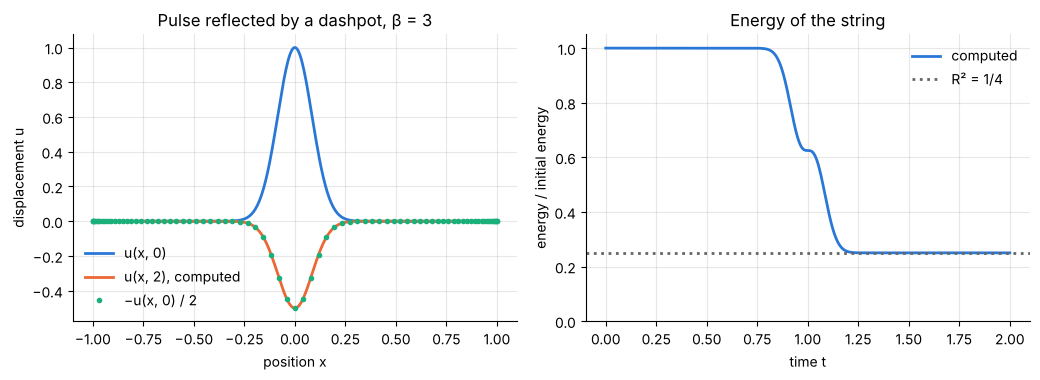

In [11]:
def wave_system(N, right_end, beta=1.0):
    """Matrix M of d/dt [u; v] = M [u; v] for u_tt = u_xx: left end fixed, right end 'fixed', 'free', 'absorbing' or 'dashpot'."""
    D, x = cheb(N)
    D2, n = D @ D, N + 1
    zero, I = np.zeros((n, n)), np.eye(n)
    if right_end == "free":
        E = np.eye(n)                                 # E u: the same values, with u_0 replaced by the value that makes (Du)_0 = 0
        E[0, :] = -D[0, :] / D[0, 0]
        E[0, 0] = 0.0
        M = np.block([[zero, E], [E @ D2 @ E, zero]])
    else:
        M = np.block([[zero, I], [D2, zero]])
        M[0, :] = M[n, :] = 0.0                       # rows of u_0 and v_0: fixed end
        if right_end == "absorbing":
            M[0, :n] = -D[0, :]                       # du_0/dt = -(Du)_0
            M[n, n:] = -D[0, :]                       # dv_0/dt = -(Dv)_0
        if right_end == "dashpot":
            M[0, :n] = -D[0, :] / beta                # du_0/dt = -(Du)_0 / β
            M[n, n:] = -D[0, :] / beta                # dv_0/dt = -(Dv)_0 / β
    M[N, :] = M[n + N, :] = 0.0                       # rows of u_N and v_N: the left end x = -1 is fixed
    return M, D, x

def run_pulse(N, right_end, beta=1.0, t_end=2.0):
    """RK4 from the right-moving pulse of 13.5. Returns x, the initial and final u, the times and the energy history."""
    M, D, x = wave_system(N, right_end, beta)
    eigenvalues = np.linalg.eigvals(M)
    assert eigenvalues.real.max() < 1e-8              # stability first: nothing in the right half-plane
    weights = clenshaw_curtis(N)[1]
    energy_of = lambda W: 0.5 * weights @ (W[N + 1:] ** 2 + (D @ W[:N + 1]) ** 2)
    u0 = np.exp(-(x / 0.12) ** 2)
    W = np.concatenate([u0, 2 * x / 0.12**2 * u0])    # v = u_t = -u_x for a right-moving pulse
    n_steps = int(np.ceil(t_end * np.abs(eigenvalues).max() / 2))
    dt = t_end / n_steps
    energy = [energy_of(W)]
    for step in range(n_steps):
        W = rk4_step(lambda q: M @ q, W, dt)
        energy.append(energy_of(W))
    return x, u0, W[:N + 1], dt * np.arange(n_steps + 1), np.array(energy)

beta = 3.0
x, u0, u_end, times, energy = run_pulse(80, "dashpot", beta)
reflection = (1 - beta) / (1 + beta)
print(f"β = {beta:.0f}: reflection coefficient {reflection:+.2f}")
print(f"energy at t = 2 / initial energy: {energy[-1] / energy[0]:.10f}    largest |u(x, 2) + u(x, 0)/2|: {np.abs(u_end - reflection * u0).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
x_fine = np.linspace(-1, 1, 401)
axes[0].plot(x_fine, barycentric_interpolate(u0, x_fine), label="u(x, 0)")
axes[0].plot(x_fine, barycentric_interpolate(u_end, x_fine), label="u(x, 2), computed")
axes[0].plot(x, -u0 / 2, "o", ms=3, label="−u(x, 0) / 2")
axes[0].set(xlabel="position x", ylabel="displacement u", title="Pulse reflected by a dashpot, β = 3")
axes[0].legend(frameon=False, loc="lower left")
axes[1].plot(times, energy / energy[0], label="computed")
axes[1].axhline(0.25, color="0.4", ls=":", label="R² = 1/4")
axes[1].set(xlabel="time t", ylabel="energy / initial energy", ylim=(0, 1.05), title="Energy of the string")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()

In [12]:
# verify: the reflection coefficient derived by hand, the energy, and the three limits of β
assert np.abs(u_end - reflection * u0).max() < 1e-6
assert abs(energy[-1] / energy[0] - 0.25) < 1e-6
assert (np.diff(energy) < 1e-9 * energy[0]).all()                                             # a dashpot only removes energy (up to the time-stepping error, about 1e-10 per step)
assert np.abs(run_pulse(80, "dashpot", 1.0)[2]).max() < 1e-8                                   # β = 1: absorbing
assert np.abs(run_pulse(80, "dashpot", 1e9)[2] + u0).max() < 1e-6                              # β → ∞: fixed
x_free, _, u_free, _, _ = run_pulse(80, "dashpot", 1 / 3)                                      # β = 1/3: R = +1/2, towards the free end
assert np.abs(u_free - u0 / 2).max() < 1e-6

**Answer.** With $\beta = 3$ the reflection coefficient is $R = (1 - 3)/(1 + 3) = -\tfrac12$.
The computed solution at $t = 2$ differs from $-\tfrac12u(x, 0)$ by at most $4\times10^{-8}$,
and the energy remaining is $0.2500000$ of the initial energy, that is $R^2 = \tfrac14$. The
dashpot absorbs three quarters of the energy of the pulse in the single encounter. Only the
matched value $\beta = 1$ absorbs all of it, which is why a terminating impedance has to equal
the characteristic impedance of the line.